In [ ]:
import torch
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from utils5 import MetaBeamMR_MLP, predict_stress #import the model scheme

# Configura la GPU se disponibile (altrimenti usa la CPU in automatico)
#device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#device = 'cpu'
# ==========================================
# Load trained model
# ==========================================

# 2. Crea il modello "vuoto" (sapendo che hai 3 input e 1 output)
model_trained = MetaBeamMR_MLP(n_input=3, n_output=1)

# 3. Riempi il modello vuoto con i pesi ("l'intelligenza") dal file .pth
# map_location=device assicura che funzioni anche se passi da un PC con GPU a uno senza
#model_trained.load_state_dict(torch.load("metabeam_mlp_model.pth", map_location=device))
model_trained.load_state_dict(torch.load("metabeam_mlp_model.pth"))

# 4. Metti il modello in modalità valutazione (CRITICO!) e spostalo sul device
model_trained.eval()
#model_trained.to(device)

# 5. Carica gli scaler per la conversione dei numeri
scaler_x = joblib.load('scaler_x.pkl')
scaler_y = joblib.load('scaler_y.pkl')

print("Modello caricato con successo e pronto all'uso!")

# ==========================================
# TEST EXAMPLE
# ==========================================

# Ora puoi usarlo all'infinito per fare tutte le previsioni che vuoi
nuovo_stress = predict_stress(
    model=model_trained,
    scaler_x=scaler_x,
    scaler_y=scaler_y,
    B=1.2,
    L=40,
    Strain=0.05195,
    #device=device
)

print(f"Lo stress predetto è: {nuovo_stress:.4f} Pa")

Modello caricato con successo e pronto all'uso!
Lo stress predetto è: 387703.9688 Pa


In [ ]:
# ==========================================
# LOAD DATASET
# ==========================================

# 1. Load dataset
column_names = [
    "B_vec", "L_vec", "TPU_R_mat", "MR_L_mat",
    "MR_R_mat", "TPU_th_mat", "Tempo_3D",
    "Strain_3D", "Stress_3D"
    ]

df = pd.read_csv('Dataset_2D.txt', sep=r'\s+', header=None, names=column_names, index_col=False)

x = df[['B_vec', 'L_vec', 'Strain_3D']].values
y = df['Stress_3D'].values.reshape(-1, 1)

print("Dataset caricato\n")

Dataset caricato



Dataset originale caricato con successo!

--- ERRORE DI PREDIZIONE PER L = 40 mm ---
B = 0.0 T | RMSE: 0.0022 MPa
B = 0.2 T | RMSE: 0.0016 MPa
B = 0.4 T | RMSE: 0.0015 MPa
B = 0.6 T | RMSE: 0.0019 MPa
B = 0.8 T | RMSE: 0.0023 MPa
B = 1.0 T | RMSE: 0.0026 MPa
B = 1.2 T | RMSE: 0.0035 MPa
---------------------------------------------


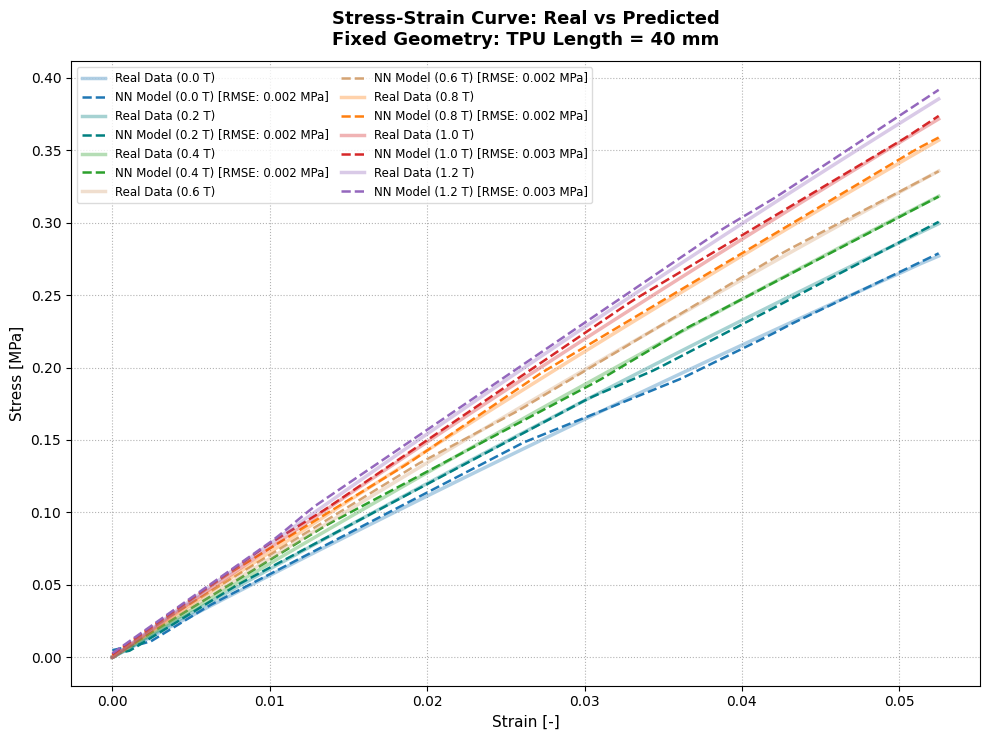

In [ ]:
import torch
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from utils5 import MetaBeamMR_MLP

# ==========================================
# 1. LOAD MODEL & SCALERS
# ==========================================
model_trained = MetaBeamMR_MLP(n_input=3, n_output=1)
model_trained.load_state_dict(torch.load("metabeam_mlp_model.pth"))
model_trained.eval()

scaler_x = joblib.load('scaler_x.pkl')
scaler_y = joblib.load('scaler_y.pkl')

# ==========================================
# 2. LOAD DATASET
# ==========================================
column_names = [
    "B_vec", "L_vec", "TPU_R_mat", "MR_L_mat",
    "MR_R_mat", "TPU_th_mat", "Tempo_3D",
    "Strain_3D", "Stress_3D"
]
df = pd.read_csv('Dataset_2D.txt', sep=r'\s+', header=None, names=column_names, index_col=False)

print("Dataset originale caricato con successo!\n")

"""
# ==========================================
# 3. EXPANDED MULTI-B FIELD SWEEP & PERFORMANCE TRACKING
# ==========================================
L_target = 40
B_targets = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2]

custom_colors = [
    "#1f77b4",  # 0.0 T
    "#008080",  # 0.2 T
    "#2ca02c",  # 0.4 T
    "#d4a373",  # 0.6 T
    "#ff7f0e",  # 0.8 T
    "#d62728",  # 1.0 T
    "#9467bd"   # 1.2 T
]

plt.figure(figsize=(10, 7.5))

print(f"--- ERRORE DI PREDIZIONE PER L = {L_target} mm ---")

for idx, B_val in enumerate(B_targets):
    # Find exact matching B channel
    available_B_values = df["B_vec"].unique()
    exact_B_match = available_B_values[np.argmin(np.abs(available_B_values - B_val))]

    df_filtered = df[(df["B_vec"] == exact_B_match) & (df["L_vec"] == L_target)].copy()

    if df_filtered.empty:
        print(f"Warning: Nessun dato trovato per B vicino a {B_val} T, salto...")
        continue

    df_filtered = df_filtered.sort_values(by="Strain_3D")

    true_strain = df_filtered["Strain_3D"].values
    true_stress = df_filtered["Stress_3D"].values

    # Vectorized Prediction Matrix Construction
    n_points = len(true_strain)
    B_array = np.full(n_points, exact_B_match)
    L_array = np.full(n_points, L_target)

    x_nuovi = np.column_stack((B_array, L_array, true_strain))

    # Scale inputs and pass through the model
    x_scaled = scaler_x.transform(x_nuovi)
    x_tensor = torch.FloatTensor(x_scaled)

    with torch.no_grad():
        predicted_scaled = model_trained(x_tensor).cpu().numpy()

    predicted_stress = scaler_y.inverse_transform(predicted_scaled).flatten()

    # --- CRITICAL PERFORMANCE METRIC CALCULATION ---
    # Calculate Root Mean Squared Error in physical units (Pa)
    field_rmse = np.sqrt(np.mean((predicted_stress - true_stress) ** 2))
    print(f"B = {exact_B_match:.1f} T | RMSE: {field_rmse:.2f} Pa")

    curve_color = custom_colors[idx]

    # 1. Real Data (COMSOL Baseline)
    plt.plot(
        true_strain,
        true_stress,
        color=curve_color,
        linestyle="-",
        linewidth=2.5,
        alpha=0.35,
        label=f"Real Data ({exact_B_match:.1f} T)"
    )

    # 2. NN Prediction (Surrogate Model)
    # Note: Added the calculated RMSE value directly into the legend label text string
    plt.plot(
        true_strain,
        predicted_stress,
        color=curve_color,
        linestyle="--",
        linewidth=1.8,
        alpha=1.0,
        label=f"NN Model ({exact_B_match:.1f} T) [RMSE: {field_rmse:.1f} Pa]"
    )

print("-" * 45)

# Formatting the publication graphic
plt.title(
    f"Stress-Strain Curve: Real vs Predicted\nFixed Geometry: TPU Length = {L_target} mm",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
plt.xlabel("Strain [-]", fontsize=11)
plt.ylabel("Stress [Pa]", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6, color="gray")

plt.legend(
    fontsize=8.5,
    loc="upper left",
    frameon=True,
    facecolor="white",
    edgecolor="#d3d3d3",
    ncol=2,
    columnspacing=1.0
)

plt.tight_layout()
plt.show()
"""

# ==============================================================================
# 3. EXPANDED MULTI-B FIELD SWEEP & PERFORMANCE TRACKING (IN MPa)
# ==============================================================================
L_target = 40
B_targets = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2]

custom_colors = [
    "#1f77b4",  # 0.0 T
    "#008080",  # 0.2 T
    "#2ca02c",  # 0.4 T
    "#d4a373",  # 0.6 T
    "#ff7f0e",  # 0.8 T
    "#d62728",  # 1.0 T
    "#9467bd"   # 1.2 T
]

plt.figure(figsize=(10, 7.5))

print(f"--- ERRORE DI PREDIZIONE PER L = {L_target} mm ---")

for idx, B_val in enumerate(B_targets):
    # Find exact matching B channel
    available_B_values = df["B_vec"].unique()
    exact_B_match = available_B_values[np.argmin(np.abs(available_B_values - B_val))]

    df_filtered = df[(df["B_vec"] == exact_B_match) & (df["L_vec"] == L_target)].copy()

    if df_filtered.empty:
        print(f"Warning: Nessun dato trovato per B vicino a {B_val} T, salto...")
        continue

    df_filtered = df_filtered.sort_values(by="Strain_3D")

    true_strain = df_filtered["Strain_3D"].values

    # 🌟 CONVERSIONE: Trasformiamo lo stress reale da Pa a MPa
    true_stress_mpa = df_filtered["Stress_3D"].values / 1e6

    # Vectorized Prediction Matrix Construction
    n_points = len(true_strain)
    B_array = np.full(n_points, exact_B_match)
    L_array = np.full(n_points, L_target)

    x_nuovi = np.column_stack((B_array, L_array, true_strain))

    # Scale inputs and pass through the model
    x_scaled = scaler_x.transform(x_nuovi)
    x_tensor = torch.FloatTensor(x_scaled)

    with torch.no_grad():
        predicted_scaled = model_trained(x_tensor).cpu().numpy()

    # 🌟 CONVERSIONE: Trasformiamo lo stress predetto da Pa a MPa
    predicted_stress_mpa = scaler_y.inverse_transform(predicted_scaled).flatten() / 1e6

    # --- CRITICAL PERFORMANCE METRIC CALCULATION (In MPa) ---
    # Calcolo dell'RMSE direttamente in MPa per coerenza con gli assi
    field_rmse_mpa = np.sqrt(np.mean((predicted_stress_mpa - true_stress_mpa) ** 2))
    print(f"B = {exact_B_match:.1f} T | RMSE: {field_rmse_mpa:.4f} MPa")

    curve_color = custom_colors[idx]

    # 1. Real Data (COMSOL Baseline) - Plottato in MPa
    plt.plot(
        true_strain,
        true_stress_mpa,
        color=curve_color,
        linestyle="-",
        linewidth=2.5,
        alpha=0.35,
        label=f"Real Data ({exact_B_match:.1f} T)"
    )

    # 2. NN Prediction (Surrogate Model) - Plottato in MPa
    plt.plot(
        true_strain,
        predicted_stress_mpa,
        color=curve_color,
        linestyle="--",
        linewidth=1.8,
        alpha=1.0,
        label=f"NN Model ({exact_B_match:.1f} T) [RMSE: {field_rmse_mpa:.3f} MPa]"
    )

print("-" * 45)

# Formatting the publication graphic
plt.title(
    f"Stress-Strain Curve: Real vs Predicted\nFixed Geometry: TPU Length = {L_target} mm",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
plt.xlabel("Strain [-]", fontsize=11)
plt.ylabel("Stress [MPa]", fontsize=11)  # 🌟 Aggiornata l'unità di misura sull'asse Y
plt.grid(True, linestyle=":", alpha=0.6, color="gray")

plt.legend(
    fontsize=8.5,
    loc="upper left",
    frameon=True,
    facecolor="white",
    edgecolor="#d3d3d3",  # 🌟 FISSATO: tutto in minuscolo
    ncol=2,
    columnspacing=1.0
)

plt.tight_layout()
plt.show()

In [ ]:
 # 5. PLOT DELLA CURVA DI CONFRONTO
plt.figure(figsize=(8, 6))

    # True output: linea blu, spessa e leggermente trasparente
plt.plot(true_strain, true_stress, 'b-', linewidth=1.5, label='Real data')

    # Predicted output: linea rossa, sottile e tratteggiata per vedere se combacia
plt.plot(true_strain, predicted_stress, 'r--', linewidth=1.5, alpha=0.7, label='NN model')

plt.title(f'Stress-Strain Curve (B = {B_target} T, L = {L_target} mm)')
plt.xlabel('Strain [1]')
plt.ylabel('Stress [Pa]')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.show()

NameError: name 'true_stress' is not defined

<Figure size 800x600 with 0 Axes>